# Orbital geometry and conditional cycle bounds

Phase 4 supporting calculations, not a feasible launcher design. The reviewed architecture uses fixed deployed slings, two A-frames, four powered and four passive fore/aft wheels. See [the review report](../docs/orbit_cycle_review.md) for equations, sources and limitations.

In [1]:
from pathlib import Path
import sys
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "lunar_slings/hub_study/config.py").is_file())
if str(repo) not in sys.path: sys.path.insert(0, str(repo))
from dataclasses import asdict
from pprint import pprint
from IPython.display import Image, Markdown, display
from lunar_slings.hub_study.study_inputs import OrbitCycleStudy
from lunar_slings.hub_study.run_orbit_cycle import write_results
study = OrbitCycleStudy()
results = write_results(study)
output_dir = repo / "lunar_slings/hub_study/results"
pprint(results["versions"])

{'matplotlib': '3.11.2',
 'numpy': '2.5.4',
 'python': '3.12.14',
 'scipy': '1.18.1'}


## 1. Inputs and provenance

SI internally. Environment constants are sourced in environment.py; mission targets in config.py; illustrative control/scale inputs in study_inputs.py. Tip tangent height is not pole height. Efficiencies and timing allowances are unverified sensitivities.

In [2]:
pprint(asdict(study))
pprint(results["environment_derived"])

{'climber_mass_ratio_sensitivities': (0.0, 0.01, 0.1),
 'environment': {'earth_g_m_s2': 9.80665,
                 'mu_m3_s2': 4902800118000.0,
                 'reference_radius_m': 1738100.0,
                 'sidereal_rotation_s': 2360592.0,
                 'solar_day_s': 2551392.0,
                 'solar_irradiance_w_m2': 1361.0,
                 'year_s': 31557600.0},
 'illustrative_apex_radius_m': 50.0,
 'illustrative_climber_efficiency': 0.8,
 'illustrative_countermass_kg': 100.0,
 'illustrative_loading_s': 60.0,
 'illustrative_payload_kg': 100.0,
 'illustrative_radial_travel_accel_m_s2': 1.0,
 'illustrative_settle_s': 60.0,
 'illustrative_tip_offset_m': 3000.0,
 'illustrative_travel_speeds_m_s': (0.5, 1.0, 5.0, 10.0),
 'illustrative_wheel_efficiency': 0.85,
 'minimum_solar_elevation_deg': 10.0,
 'mission': {'assembly_count': 2,
             'catcher_altitude_m': 20000.0,
             'climber_count': 2,
             'electrical_storage_allowed': False,
             'flywheel_b

## 2. Point-launch comparison and site-relative repeat

The zero-size equatorial apoapsis transfer is a regression comparison. The next section uses the actual off-equator tip position.

In [3]:
pprint(results["point_reference"])

{'catch_relative_m_s': 4.783287336584181,
 'catcher_phase_at_release_rad': 0.026765722347861676,
 'flight_s': 3279.2700907552817,
 'orbit_period_s': 6614.897747879624,
 'prograde_site_m_s': 1679.6888885413991,
 'release_inertial_m_s': 1684.3151875301312,
 'retrograde_site_m_s': 1688.9414865188633,
 'site_revisit_s': 6633.486234646569}


## 3. Finite horizontal-sling node intercept

Purely eastward release occurs at a tip north/south of the hub. The first equator crossing is 90 degrees along its inclined orbit. Setting semilatus rectum equal to catcher radius gives the derived node solution.

{'catch_relative_m_s': 19.2364839125561,
 'flight_s': 1629.823971479241,
 'inclination_deg': 0.032964544213515384,
 'numerical_position_error_m': 6.999412970914307e-10,
 'site_tip_speed_m_s': np.float64(1684.5240132286133),
 'tip_offset_m': 1000.0}
{'catch_relative_m_s': 19.425271567963062,
 'flight_s': 1629.826716508412,
 'inclination_deg': 0.0988935453463783,
 'numerical_position_error_m': 4.114564966257581e-10,
 'site_tip_speed_m_s': np.float64(1684.52177669069),
 'tip_offset_m': 3000.0}
{'catch_relative_m_s': 21.456103939452344,
 'flight_s': 1629.8579410502696,
 'inclination_deg': 0.3296418413158088,
 'numerical_position_error_m': 2.8431686463833192e-09,
 'site_tip_speed_m_s': np.float64(1684.4963366970755),
 'tip_offset_m': 10000.0}


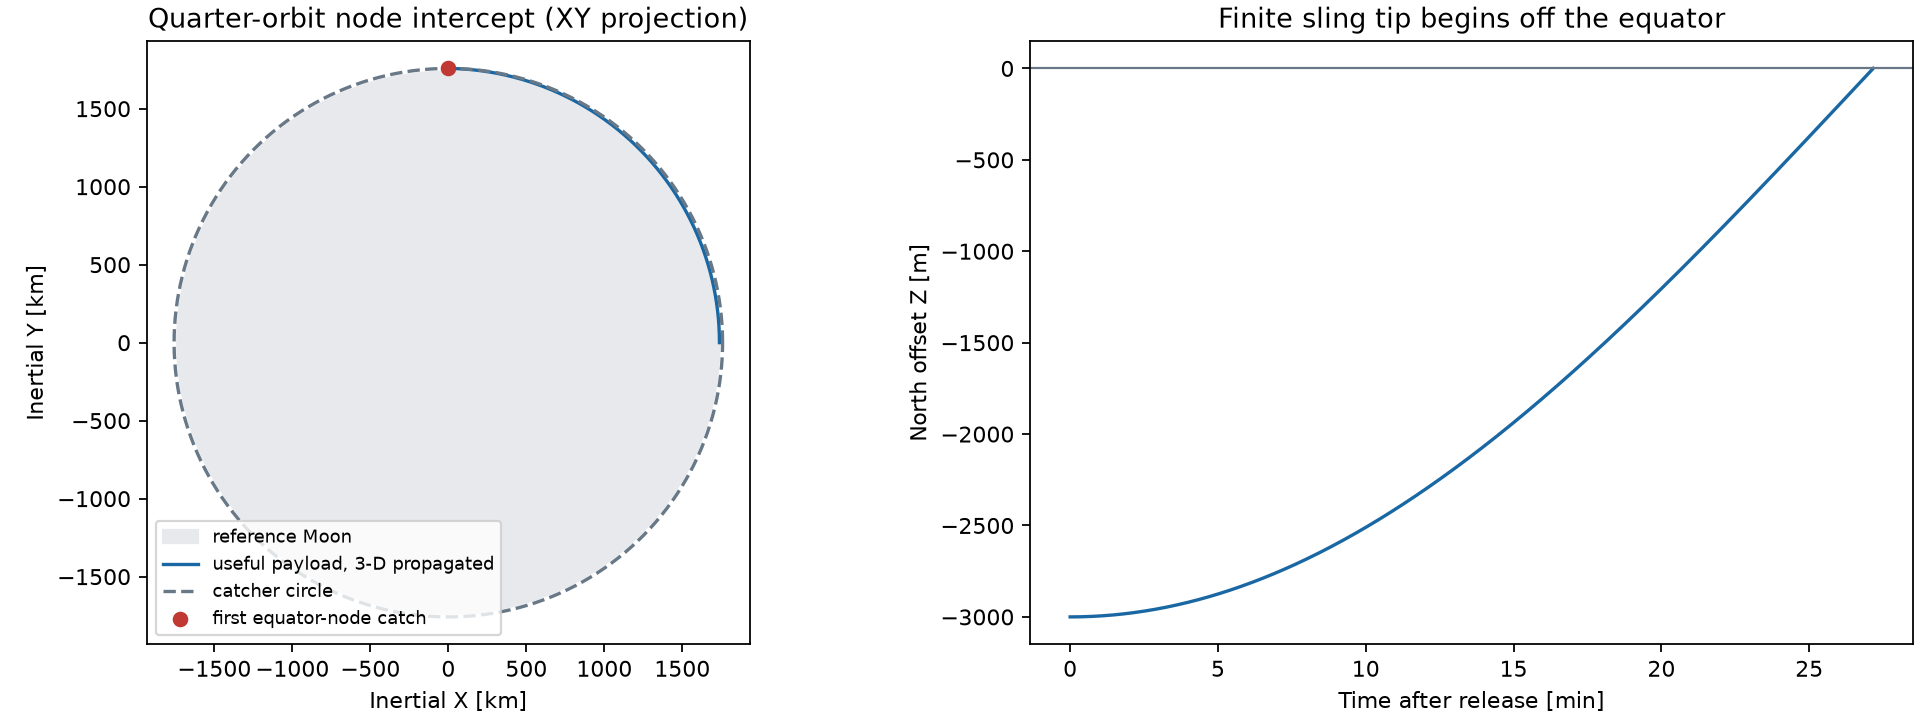

In [4]:
for case in results["finite_tip_cases"]:
    pprint({k: case[k] for k in ["tip_offset_m", "inclination_deg", "site_tip_speed_m_s", "flight_s", "catch_relative_m_s", "numerical_position_error_m"]})
display(Image(filename=str(output_dir / "orbit_node.png")))

## 4. Countermass trajectories

Equal-radius and 1% shorter rock-side radii are separate geometric cases. The cycle example below remains equal-radius; do not combine these into an asserted feasible design. Spherical impact coordinates do not establish disposal safety.

{'apoapsis_altitude_m': 1579.3845615503378,
 'impacts_reference_sphere': False,
 'periapsis_altitude_m': 5.5890277770813555}
{'apoapsis_altitude_m': 5.537505992222577,
 'impact_ground_relative_m_s': 1667.6819477189222,
 'impact_inertial_m_s': 1663.0556557767,
 'impact_latitude_rad': 0.0017084842505854382,
 'impact_longitude_rad': -0.017944383484138182,
 'impact_s': 18.702140141093913,
 'impacts_reference_sphere': True,
 'periapsis_altitude_m': -66521.01458803983}


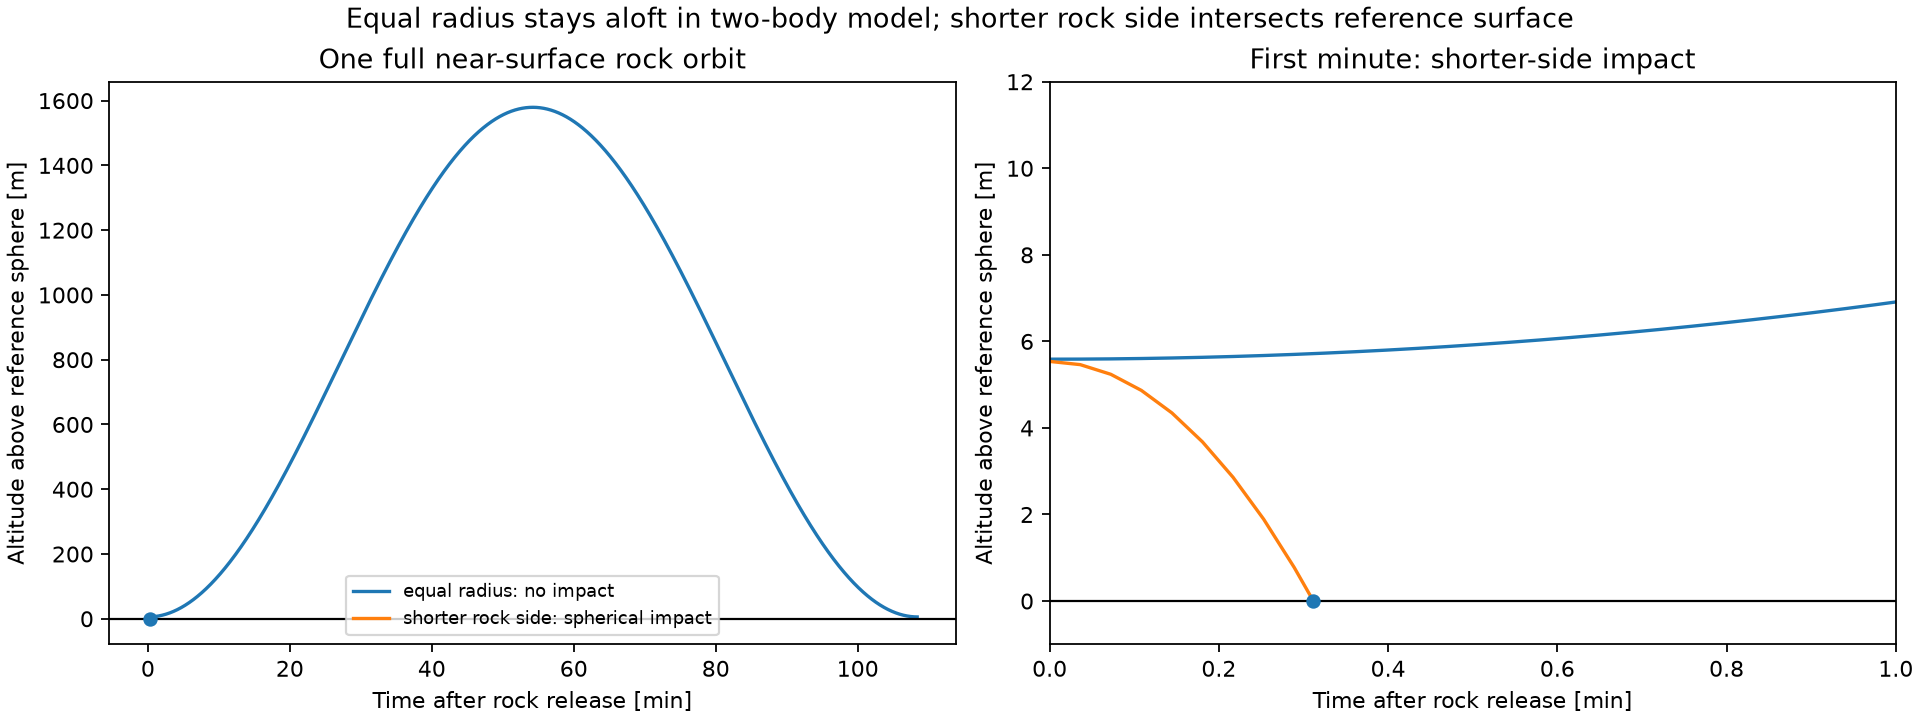

In [5]:
case = results["finite_tip_cases"][1]
pprint(case["equal_radius_counter"])
pprint(case["shorter_radius_counter"])
display(Image(filename=str(output_dir / "countermass_altitude.png")))

## 5. Complete-cycle kinematic bound and phase closure

Includes rest-to-rest outward and return travel, selected loading/settling allowances, and skipped site-relative passes. Fixed-speed rotation alone does not close the release phase.

In [6]:
for case in results["cycles"]: pprint(case)
print("Required phase correction [rad]", results["required_phase_integral_correction_rad"])
print("Mean correction over slack time [rad/s]", results["ideal_phase_correction_mean_rad_s"])

{'dumped_energy_j': 283635653.2622274,
 'electrical_energy_j': 667378007.6758292,
 'launch_interval_s': 13266.972469293138,
 'minimum_cycle_s': 11921.0,
 'passes_skipped': 1,
 'peak_electrical_w': 222512.48713058137,
 'phase_wait_budget_s': 1345.9724692931377,
 'travel_speed_m_s': 0.5,
 'trip_s': 5900.5}
{'dumped_energy_j': 283670547.42859125,
 'electrical_energy_j': 667460111.5966853,
 'launch_interval_s': 6633.486234646569,
 'minimum_cycle_s': 6022.0,
 'passes_skipped': 0,
 'peak_electrical_w': 444971.1245151858,
 'phase_wait_budget_s': 611.4862346465688,
 'travel_speed_m_s': 1.0,
 'trip_s': 2951.0}
{'dumped_energy_j': 283682034.4558227,
 'electrical_energy_j': 667487139.8960534,
 'launch_interval_s': 6633.486234646569,
 'minimum_cycle_s': 1310.0,
 'passes_skipped': 0,
 'peak_electrical_w': 2216092.774985365,
 'phase_wait_budget_s': 5323.486234646569,
 'travel_speed_m_s': 5.0,
 'trip_s': 595.0}
{'dumped_energy_j': 283682468.694455,
 'electrical_energy_j': 667488161.6340117,
 'launch_

## 6. Instantaneous power with no recovery credit

Straight-sling constant-spin moving-mass calculation only. Positive wheel/radial-drive work is charged through explicit efficiencies; braking energy is dissipated. Climber mass is unsized: primary comparison uses the zero-mass limit; nonzero masses are sensitivities. Outward radial braking is energy output, while the wheel drive supplies torque under the constant-spin assumption. See [radial energy clarification](../docs/radial_energy_review.md). Rolling loss, auxiliary demand, cable dynamics and phase-correction power are not included.

[{'each_climber_kg': 0.0,
  'each_climber_to_payload_ratio': 0.0,
  'electrical_energy_j': 667488161.6340117,
  'outbound': {'dumped_energy_j': 283682468.694455,
               'electrical_energy_j': 667488161.6340117,
               'peak_electrical_w': 4376008.218968744,
               'peak_radial_braking_available_w': 1860189.2012156094,
               'peak_radial_drive_input_w': 0.0,
               'peak_wheel_input_w': 4376008.218968744,
               'radial_braking_energy_j': 283682468.694455,
               'radial_input_energy_j': 0.0,
               'wheel_input_energy_j': 667488161.6340117},
  'peak_electrical_w': 4376008.218968744,
  'returning': {'dumped_energy_j': 0.0,
                'electrical_energy_j': 0.0,
                'peak_electrical_w': 0.0,
                'peak_radial_braking_available_w': 0.0,
                'peak_radial_drive_input_w': 0.0,
                'peak_wheel_input_w': 0.0,
                'radial_braking_energy_j': 0.0,
                'radia

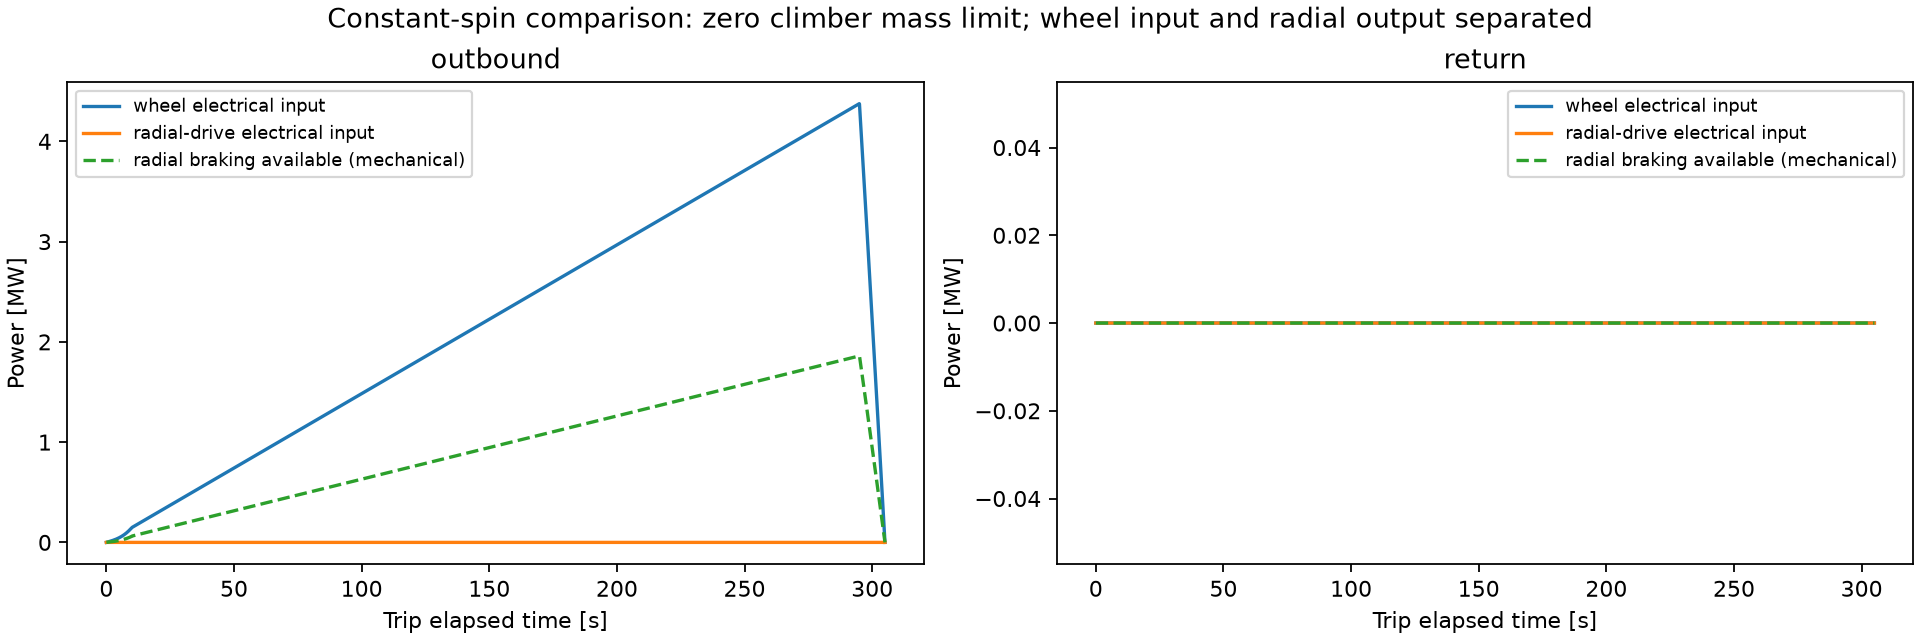

In [7]:
pprint(results["climber_mass_sensitivity"])
display(Image(filename=str(output_dir / "cycle_power_bound.png")))

## 7. Sunlight availability and conditional throughput

10-degree minimum solar elevation is an operating-window assumption, not panel sizing. No operation or electrical buffering through night is assumed.

In [8]:
pprint(results["sun"])

{'available_fraction': 0.4444444444444444,
 'conditional_catches_per_year': 2102.6921774466646,
 'conditional_payload_kg_year': 210269.21774466644,
 'ideal_complete_cycles_per_solar_day': 170,
 'night_or_low_sun_s': 1417440.0,
 'operating_window_s': 1133952.0}


## 8. Generated tables and open feasibility requirements

A sustainable 20 km equatorial catcher orbit needs gravity-harmonic and terrain checks. Tether droop, unloaded-cable behavior, stabilizer/structural loads, climber contact, phase-restoration control and installed panel mass remain unresolved. No optimization is performed.

In [9]:
display(Markdown((output_dir / "orbit_cycle_tables.md").read_text()))

# Phase 4 generated numerical tables

Illustrative two-body and straight-sling bounds; **not a feasible launcher design**.

| Point-equatorial reference quantity | Value |
| --- | ---: |
| Catcher orbit period [min] | 110.248296 |
| Site-relative revisit [min] | 110.558104 |
| Prograde site release speed [m/s] | 1679.688889 |
| Retrograde site release speed [m/s] | 1688.941487 |
| Surface-to-apoapsis flight [min] | 54.654502 |
| Apoapsis mismatch [m/s] | 4.783287 |

| Tip offset [km] | Inclination [deg] | Site tip speed [m/s] | Flight [min] | Catch mismatch [m/s] | Actual centripetal Earth-g | Max wheel radius [m] |
| ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 1.0 | 0.032965 | 1684.524013 | 27.163733 | 19.236484 | 289.357 | 21.229 |
| 3.0 | 0.098894 | 1684.521777 | 27.163779 | 19.425272 | 96.452 | 63.686 |
| 10.0 | 0.329642 | 1684.496337 | 27.164299 | 21.456104 | 28.935 | 212.289 |

| Tip offset [km] | Equal-radius rock minimum altitude [m] | Equal-radius impact? | Shorter-side impact time [s] | Impact latitude [deg] | Relative longitude [deg] | Impact ground speed [m/s] |
| ---: | ---: | --- | ---: | ---: | ---: | ---: |
| 1.0000 | 3.2877 | False | 14.3983 | 0.0326 | -0.7915 | 1667.6820 |
| 3.0000 | 5.5890 | False | 18.7021 | 0.0979 | -1.0281 | 1667.6819 |
| 10.0000 | 31.7668 | False | 44.3746 | 0.3261 | -2.4395 | 1667.6817 |

Counter radius fraction = 0.99; this changes geometry, not just rock mass. Impact safety remains unverified.

| Radial speed [m/s] | One trip [s] | Minimum full cycle [s] | Catcher passes skipped | Peak electric bound [MW] | Cycle electric energy [MJ] |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 0.5 | 5900.500 | 11921.000 | 1 | 0.2225 | 667.378 |
| 1.0 | 2951.000 | 6022.000 | 0 | 0.4450 | 667.460 |
| 5.0 | 595.000 | 1310.000 | 0 | 2.2161 | 667.487 |
| 10.0 | 305.000 | 730.000 | 0 | 4.3760 | 667.488 |

Main cycle table uses zero climber mass as a comparison limit, not a sized climber.

| Each climber / payload mass | Each climber [kg] | Outbound wheel peak [MW electric] | Outbound radial braking peak [MW mechanical] | Return radial-drive peak [MW electric] | Cycle electric [MJ, no recovery] |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 0.00 | 0.0 | 4.3760 | 1.8602 | 0.0000 | 667.488 |
| 0.01 | 1.0 | 4.4198 | 1.8788 | 0.0233 | 677.709 |
| 0.10 | 10.0 | 4.8136 | 2.0462 | 0.2325 | 769.697 |

10° sun-elevation availability: 0.444444 of solar day.
Illustrative conditional catches/year: 2102.692.
Fixed-spin phase mismatch each site revisit: -1.178215 rad.

See [interpretation and limitations](../docs/orbit_cycle_review.md).
